In [1]:
import sys
import sklearn
import pandas
import numpy
import lightgbm
import joblib

print("Python:", sys.version)
print("scikit-learn:", sklearn.__version__)
print("pandas:", pandas.__version__)
print("numpy:", numpy.__version__)
print("lightgbm:", lightgbm.__version__)
print("joblib:", joblib.__version__)

Python: 3.13.9 | packaged by Anaconda, Inc. | (main, Oct 21 2025, 19:09:58) [MSC v.1929 64 bit (AMD64)]
scikit-learn: 1.7.2
pandas: 2.3.3
numpy: 2.3.5
lightgbm: 4.7.0
joblib: 1.5.2


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [3]:
data = "C:/Users/Admin/Downloads/Machine Learning midterm project/online_shoppers_purchasing_intention_dataset/online_shoppers_intention.csv"

df = pd.read_csv(data)

In [4]:
df.head()

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


In [5]:
df.shape

(12330, 18)

In [6]:
df.columns

Index(['Administrative', 'Administrative_Duration', 'Informational',
       'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration',
       'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay', 'Month',
       'OperatingSystems', 'Browser', 'Region', 'TrafficType', 'VisitorType',
       'Weekend', 'Revenue'],
      dtype='object')

In [7]:
df.dtypes

Administrative               int64
Administrative_Duration    float64
Informational                int64
Informational_Duration     float64
ProductRelated               int64
ProductRelated_Duration    float64
BounceRates                float64
ExitRates                  float64
PageValues                 float64
SpecialDay                 float64
Month                       object
OperatingSystems             int64
Browser                      int64
Region                       int64
TrafficType                  int64
VisitorType                 object
Weekend                       bool
Revenue                       bool
dtype: object

### EDA

In [8]:
df.columns = df.columns.str.lower().str.replace(' ','_')

In [9]:
df.head().T

,0,1,2,3,4
administrative,0,0,0,0,0
administrative_duration,0.0,0.0,0.0,0.0,0.0
informational,0,0,0,0,0
informational_duration,0.0,0.0,0.0,0.0,0.0
productrelated,1,2,1,2,10
productrelated_duration,0.0,64.0,0.0,2.666667,627.5
bouncerates,0.2,0.0,0.2,0.05,0.02
exitrates,0.2,0.1,0.2,0.14,0.05
pagevalues,0.0,0.0,0.0,0.0,0.0
specialday,0.0,0.0,0.0,0.0,0.0


In [10]:
categorical_columns = list(df.dtypes[df.dtypes == 'object'].index)

In [11]:
categorical_columns

['month', 'visitortype']

In [12]:
for c in categorical_columns:
    df[c] = df[c].str.lower().str.replace(' ','_')

In [13]:
df.head().T

,0,1,2,3,4
administrative,0,0,0,0,0
administrative_duration,0.0,0.0,0.0,0.0,0.0
informational,0,0,0,0,0
informational_duration,0.0,0.0,0.0,0.0,0.0
productrelated,1,2,1,2,10
productrelated_duration,0.0,64.0,0.0,2.666667,627.5
bouncerates,0.2,0.0,0.2,0.05,0.02
exitrates,0.2,0.1,0.2,0.14,0.05
pagevalues,0.0,0.0,0.0,0.0,0.0
specialday,0.0,0.0,0.0,0.0,0.0


In [14]:
df.revenue.value_counts()

revenue
False    10422
True      1908
Name: count, dtype: int64

In [15]:
df.revenue.value_counts(normalize=True)

revenue
False    0.845255
True     0.154745
Name: proportion, dtype: float64

### Train, validation, and test split

In [16]:
from sklearn.model_selection import train_test_split

df_full_train, df_test = train_test_split(
    df,
    test_size=0.2,
    random_state=1,
    stratify=df.revenue
)

df_train, df_val = train_test_split(
    df_full_train,
    test_size=0.25,
    random_state=1,
    stratify=df_full_train.revenue
)

len(df_train), len(df_val), len(df_test)

(7398, 2466, 2466)

In [17]:
for dataset in [df_train, df_val, df_test]:
    print(dataset.revenue.value_counts(normalize=True))
    print()

revenue
False    0.845364
True     0.154636
Name: proportion, dtype: float64

revenue
False    0.845093
True     0.154907
Name: proportion, dtype: float64

revenue
False    0.845093
True     0.154907
Name: proportion, dtype: float64



In [18]:
# Check missing values
df.isnull().sum()

administrative             0
administrative_duration    0
informational              0
informational_duration     0
productrelated             0
productrelated_duration    0
bouncerates                0
exitrates                  0
pagevalues                 0
specialday                 0
month                      0
operatingsystems           0
browser                    0
region                     0
traffictype                0
visitortype                0
weekend                    0
revenue                    0
dtype: int64

In [19]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
administrative,12330.0,2.315166,3.321784,0.0,0.000000,1.000000,4.000000,27.000000
administrative_duration,12330.0,80.818611,176.779107,0.0,0.000000,7.500000,93.256250,3398.750000
informational,12330.0,0.503569,1.270156,0.0,0.000000,0.000000,0.000000,24.000000
informational_duration,12330.0,34.472398,140.749294,0.0,0.000000,0.000000,0.000000,2549.375000
productrelated,12330.0,31.731468,44.475503,0.0,7.000000,18.000000,38.000000,705.000000
productrelated_duration,12330.0,1194.746220,1913.669288,0.0,184.137500,598.936905,1464.157214,63973.522230
bouncerates,12330.0,0.022191,0.048488,0.0,0.000000,0.003112,0.016813,0.200000
exitrates,12330.0,0.043073,0.048597,0.0,0.014286,0.025156,0.050000,0.200000
pagevalues,12330.0,5.889258,18.568437,0.0,0.000000,0.000000,0.000000,361.763742
specialday,12330.0,0.061427,0.198917,0.0,0.000000,0.000000,0.000000,1.000000


In [20]:
categorical = [
    'month',
    'operatingsystems',
    'browser',
    'region',
    'traffictype',
    'visitortype',
    'weekend'
]

numerical = [
    'administrative',
    'administrative_duration',
    'informational',
    'informational_duration',
    'productrelated',
    'productrelated_duration',
    'bouncerates',
    'exitrates',
    'pagevalues',
    'specialday'
]

for col in categorical:
    print(f'\n{col}:')
    print(df[col].value_counts())


month:
month
may     3364
nov     2998
mar     1907
dec     1727
oct      549
sep      448
aug      433
jul      432
june     288
feb      184
Name: count, dtype: int64

operatingsystems:
operatingsystems
2    6601
1    2585
3    2555
4     478
8      79
6      19
7       7
5       6
Name: count, dtype: int64

browser:
browser
2     7961
1     2462
4      736
5      467
6      174
10     163
8      135
3      105
13      61
7       49
12      10
11       6
9        1
Name: count, dtype: int64

region:
region
1    4780
3    2403
4    1182
2    1136
6     805
7     761
9     511
8     434
5     318
Name: count, dtype: int64

traffictype:
traffictype
2     3913
1     2451
3     2052
4     1069
13     738
10     450
6      444
8      343
5      260
11     247
20     198
9       42
7       40
15      38
19      17
14      13
18      10
16       3
12       1
17       1
Name: count, dtype: int64

visitortype:
visitortype
returning_visitor    10551
new_visitor           1694
other            

In [21]:
for col in categorical:
    print(f'\nPurchase rate by {col}:')
    print(
        df.groupby(col, observed=True)['revenue']
        .mean()
        .sort_values(ascending=False)
        .round(3)
    )


Purchase rate by month:
month
nov     0.254
oct     0.209
sep     0.192
aug     0.176
jul     0.153
dec     0.125
may     0.109
june    0.101
mar     0.101
feb     0.016
Name: revenue, dtype: float64

Purchase rate by operatingsystems:
operatingsystems
8    0.215
4    0.178
2    0.175
5    0.167
1    0.147
7    0.143
6    0.105
3    0.105
Name: revenue, dtype: float64

Purchase rate by browser:
browser
12    0.300
13    0.262
10    0.196
5     0.184
4     0.177
11    0.167
8     0.156
2     0.154
1     0.148
7     0.122
6     0.115
3     0.048
9     0.000
Name: revenue, dtype: float64

Purchase rate by region:
region
9    0.168
2    0.165
5    0.164
1    0.161
7    0.156
4    0.148
3    0.145
6    0.139
8    0.129
Name: revenue, dtype: float64

Purchase rate by traffictype:
traffictype
16    0.333
7     0.300
8     0.277
20    0.253
2     0.216
5     0.215
10    0.200
11    0.190
4     0.154
14    0.154
6     0.119
1     0.107
9     0.095
3     0.088
19    0.059
13    0.058
12    0.00

In [22]:
df.groupby('revenue')[
    df.select_dtypes(include=['int64', 'float64']).columns
    ].mean().T

revenue,False,True
administrative,2.117732,3.393606
administrative_duration,73.740111,119.483244
informational,0.451833,0.786164
informational_duration,30.236237,57.611427
productrelated,28.714642,48.210168
productrelated_duration,1069.987809,1876.209615
bouncerates,0.025317,0.005117
exitrates,0.047378,0.019555
pagevalues,1.975998,27.264518
specialday,0.068432,0.023166


### feature importance

In [23]:
global_purchase_rate = df.revenue.mean()
global_purchase_rate

np.float64(0.15474452554744525)

In [24]:
df.groupby('visitortype').revenue.agg(['mean', 'count'])

,mean,count
visitortype,,
new_visitor,0.249115,1694
other,0.188235,85
returning_visitor,0.139323,10551


In [25]:
purchase_rate = df.groupby('visitortype').revenue.mean()

risk_ratio = purchase_rate / global_purchase_rate

risk_ratio.sort_values(ascending=False)

visitortype
new_visitor          1.609844
other                1.216426
returning_visitor    0.900344
Name: revenue, dtype: float64

In [26]:
# risk ratios for all categorical features

for col in categorical:
    print(f'\n{col}:')

    purchase_rate = df.groupby(col, observed=True).revenue.mean()
    risk_ratio = purchase_rate / global_purchase_rate

    print(risk_ratio.sort_values(ascending=False).round(2))


month:
month
nov     1.64
oct     1.35
sep     1.24
aug     1.13
jul     0.99
dec     0.81
may     0.70
june    0.65
mar     0.65
feb     0.11
Name: revenue, dtype: float64

operatingsystems:
operatingsystems
8    1.39
4    1.15
2    1.13
5    1.08
1    0.95
7    0.92
6    0.68
3    0.68
Name: revenue, dtype: float64

browser:
browser
12    1.94
13    1.70
10    1.27
5     1.19
4     1.14
11    1.08
8     1.01
2     0.99
1     0.96
7     0.79
6     0.74
3     0.31
9     0.00
Name: revenue, dtype: float64

region:
region
9    1.09
2    1.07
5    1.06
1    1.04
7    1.01
4    0.96
3    0.94
6    0.90
8    0.83
Name: revenue, dtype: float64

traffictype:
traffictype
16    2.15
7     1.94
8     1.79
20    1.63
2     1.40
5     1.39
10    1.29
11    1.23
4     1.00
14    0.99
6     0.77
1     0.69
9     0.62
3     0.57
19    0.38
13    0.38
12    0.00
15    0.00
17    0.00
18    0.00
Name: revenue, dtype: float64

visitortype:
visitortype
new_visitor          1.61
other                1.22

In [27]:
# Mutual Information
from sklearn.metrics import mutual_info_score

def mutual_info_revenue_score(series):
    return mutual_info_score(series, df.revenue)

mi = df[categorical].apply(mutual_info_revenue_score)

mi.sort_values(ascending=False)

traffictype         0.015804
month               0.015425
visitortype         0.004911
operatingsystems    0.003215
browser             0.001197
weekend             0.000420
region              0.000381
dtype: float64

In [28]:
df[numerical + ['revenue']].corr()['revenue'].sort_values(
    ascending=False
)

revenue                    1.000000
pagevalues                 0.492569
productrelated             0.158538
productrelated_duration    0.152373
administrative             0.138917
informational              0.095200
administrative_duration    0.093587
informational_duration     0.070345
specialday                -0.082305
bouncerates               -0.150673
exitrates                 -0.207071
Name: revenue, dtype: float64

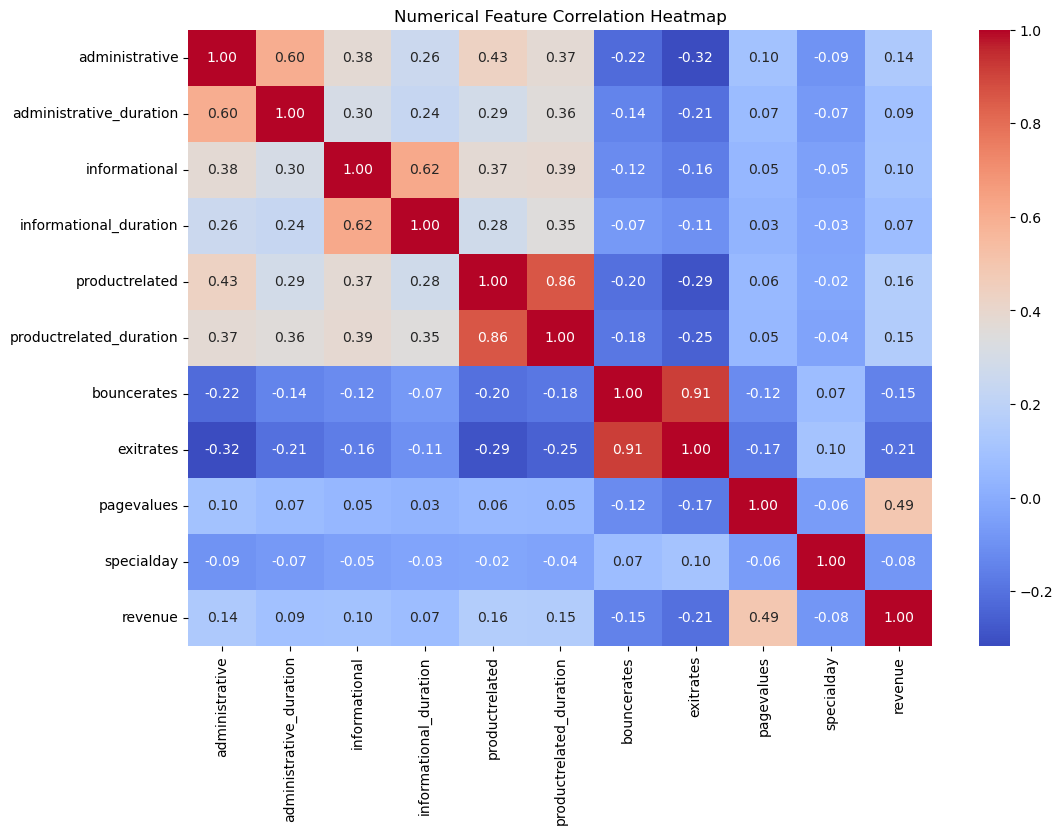

In [29]:
import seaborn as sns

plt.figure(figsize=(12, 8))

correlation = df[numerical + ['revenue']].corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Numerical Feature Correlation Heatmap')
plt.show()

### Model Training

In [30]:
from sklearn.feature_extraction import DictVectorizer

df_train_copy = df_train.copy()
df_val_copy = df_val.copy()
df_test_copy = df_test.copy()

for col in categorical:
    df_train_copy[col] = df_train_copy[col].astype(str)
    df_val_copy[col] = df_val_copy[col].astype(str)
    df_test_copy[col] = df_test_copy[col].astype(str)

train_dicts = df_train_copy[categorical + numerical].to_dict(orient='records')
val_dicts = df_val_copy[categorical + numerical].to_dict(orient='records')
test_dicts = df_test_copy[categorical + numerical].to_dict(orient='records')

dv = DictVectorizer(sparse=True)

X_train = dv.fit_transform(train_dicts)
X_val = dv.transform(val_dicts)
X_test = dv.transform(test_dicts)

y_train = df_train.revenue.values
y_val = df_val.revenue.values
y_test = df_test.revenue.values

X_train.shape, X_val.shape, X_test.shape

((7398, 72), (2466, 72), (2466, 72))

In [31]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(solver='liblinear', random_state=1)

model.fit(X_train, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,1
,solver,'liblinear'
,max_iter,100
,multi_class,'deprecated'


In [32]:
y_pred = model.predict(X_val)

y_pred[:10]

array([False, False, False, False, False, False, False, False, False,
       False])

In [33]:
from sklearn.metrics import accuracy_score

In [34]:
y_train_pred = model.predict(X_train)
y_val_pred = model.predict(X_val)

print('Training accuracy:', accuracy_score(y_train, y_train_pred))
print('Validation accuracy:', accuracy_score(y_val, y_val_pred))

Training accuracy: 0.8826709921600433
Validation accuracy: 0.8864557988645579


In [35]:
y_pred_proba = model.predict_proba(X_val)[:, 1]

y_pred_proba[:10]

array([0.37561198, 0.14398114, 0.08269402, 0.02349693, 0.11355745,
       0.05340507, 0.09923764, 0.20438087, 0.0277451 , 0.03835314])

### Confusion matrix

In [36]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_val, y_pred)

cm

array([[2032,   52],
       [ 228,  154]])

### Precision, Recall and F1

In [37]:
from sklearn.metrics import precision_score, recall_score, f1_score

print('Precision:', precision_score(y_val, y_pred))
print('Recall:', recall_score(y_val, y_pred))
print('F1:', f1_score(y_val, y_pred))

Precision: 0.7475728155339806
Recall: 0.4031413612565445
F1: 0.5238095238095238


### ROC-AUC

In [38]:
from sklearn.metrics import roc_auc_score

y_train_proba = model.predict_proba(X_train)[:, 1]
y_val_proba = model.predict_proba(X_val)[:, 1]

train_auc = roc_auc_score(y_train, y_train_proba)
val_auc = roc_auc_score(y_val, y_val_proba)

print('Training ROC-AUC:', train_auc)
print('Validation ROC-AUC:', val_auc)

Training ROC-AUC: 0.9044222886164044
Validation ROC-AUC: 0.8989986031694989


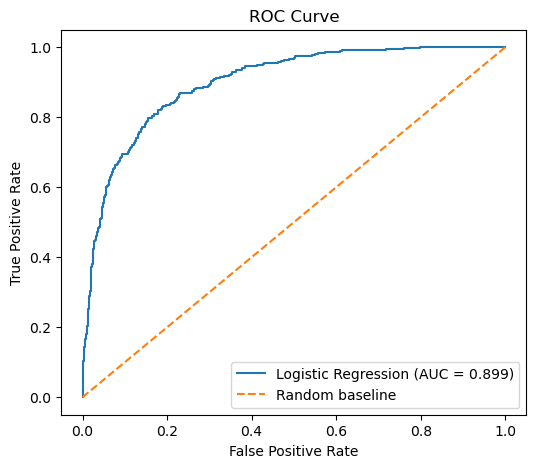

In [39]:
from sklearn.metrics import roc_curve

fpr, tpr, thresholds = roc_curve(y_val, y_pred_proba)

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f'Logistic Regression (AUC = {val_auc:.3f})')
plt.plot([0, 1], [0, 1], linestyle='--', label='Random baseline')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend()
plt.show()

### Train Decision Tree

In [40]:
from sklearn.tree import DecisionTreeClassifier

dt = DecisionTreeClassifier(
    max_depth=6,
    min_samples_leaf=20,
    random_state=1
)

dt.fit(X_train, y_train)

,criterion,'gini'
,splitter,'best'
,max_depth,6
,min_samples_split,2
,min_samples_leaf,20
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,1
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [41]:
# Predictions
y_train_pred = dt.predict(X_train)
y_val_pred = dt.predict(X_val)

# Probabilities
y_train_proba = dt.predict_proba(X_train)[:, 1]
y_val_proba = dt.predict_proba(X_val)[:, 1]

# Results
print('Training Accuracy:', accuracy_score(y_train, y_train_pred))
print('Validation Accuracy:', accuracy_score(y_val, y_val_pred))

print('Training ROC-AUC:', roc_auc_score(y_train, y_train_proba))
print('Validation ROC-AUC:', roc_auc_score(y_val, y_val_proba))

Training Accuracy: 0.9113273857799405
Validation Accuracy: 0.8880778588807786
Training ROC-AUC: 0.9345193202224703
Validation ROC-AUC: 0.9212643577091979


### Train Random Forest

In [42]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(
    n_estimators=100,
    max_depth=10,
    min_samples_leaf=10,
    random_state=1,
    n_jobs=-1
)

rf.fit(X_train, y_train)

,n_estimators,100
,criterion,'gini'
,max_depth,10
,min_samples_split,2
,min_samples_leaf,10
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [43]:
y_train_pred = rf.predict(X_train)
y_val_pred = rf.predict(X_val)

y_train_proba = rf.predict_proba(X_train)[:, 1]
y_val_proba = rf.predict_proba(X_val)[:, 1]

print('Training Accuracy:', accuracy_score(y_train, y_train_pred))
print('Validation Accuracy:', accuracy_score(y_val, y_val_pred))

print('Training ROC-AUC:', roc_auc_score(y_train, y_train_proba))
print('Validation ROC-AUC:', roc_auc_score(y_val, y_val_proba))

Training Accuracy: 0.9110570424439037
Validation Accuracy: 0.8969991889699919
Training ROC-AUC: 0.9536974657897267
Validation ROC-AUC: 0.9264855141642633


In [44]:
# Tune Random Forest
for n in [50, 100, 150, 200, 300]:
    rf = RandomForestClassifier(
        n_estimators=n,
        max_depth=10,
        min_samples_leaf=10,
        random_state=1,
        n_jobs=-1
    )

    rf.fit(X_train, y_train)

    train_auc = roc_auc_score(
        y_train, rf.predict_proba(X_train)[:, 1]
    )
    val_auc = roc_auc_score(
        y_val, rf.predict_proba(X_val)[:, 1]
    )

    print(
        f'n_estimators={n},'
        f'train_auc={train_auc:.4f},'
        f'val_auc={val_auc:.4f}'
    )

n_estimators=50,train_auc=0.9532,val_auc=0.9245
n_estimators=100,train_auc=0.9537,val_auc=0.9265
n_estimators=150,train_auc=0.9545,val_auc=0.9266
n_estimators=200,train_auc=0.9551,val_auc=0.9268
n_estimators=300,train_auc=0.9554,val_auc=0.9273


In [45]:
for depth in [6, 8, 10, 12, 15]:
    for leaf in [5, 10, 20]:
        rf = RandomForestClassifier(
            n_estimators=300,
            max_depth=depth,
            min_samples_leaf=leaf,
            random_state=1,
            n_jobs=-1
        )

        rf.fit(X_train, y_train)

        train_auc = roc_auc_score(
            y_train, rf.predict_proba(X_train)[:, 1]
        )
        val_auc = roc_auc_score(
            y_val, rf.predict_proba(X_val)[:, 1]
        )

        print(
            f'depth={depth}, leaf={leaf}, '
            f'train_auc={train_auc:.4f}, '
            f'val_auc={val_auc:.4f}'
        )

depth=6, leaf=5, train_auc=0.9373, val_auc=0.9219
depth=6, leaf=10, train_auc=0.9345, val_auc=0.9225
depth=6, leaf=20, train_auc=0.9299, val_auc=0.9206
depth=8, leaf=5, train_auc=0.9524, val_auc=0.9259
depth=8, leaf=10, train_auc=0.9471, val_auc=0.9261
depth=8, leaf=20, train_auc=0.9401, val_auc=0.9251
depth=10, leaf=5, train_auc=0.9640, val_auc=0.9266
depth=10, leaf=10, train_auc=0.9554, val_auc=0.9273
depth=10, leaf=20, train_auc=0.9455, val_auc=0.9266
depth=12, leaf=5, train_auc=0.9711, val_auc=0.9303
depth=12, leaf=10, train_auc=0.9603, val_auc=0.9284
depth=12, leaf=20, train_auc=0.9482, val_auc=0.9281
depth=15, leaf=5, train_auc=0.9764, val_auc=0.9308
depth=15, leaf=10, train_auc=0.9636, val_auc=0.9296
depth=15, leaf=20, train_auc=0.9496, val_auc=0.9283


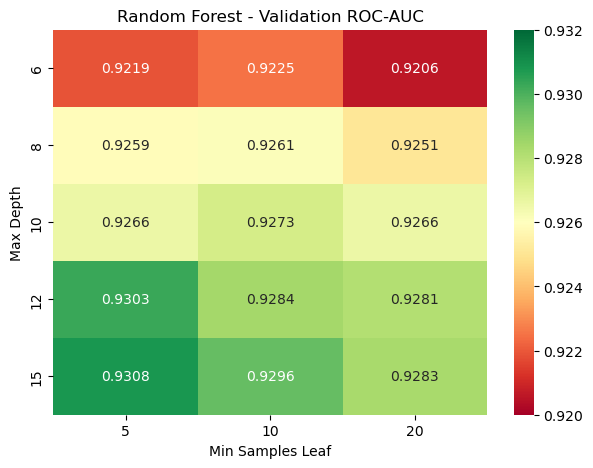

In [46]:
results = [
    (6, 5, 0.9219), (6, 10, 0.9225), (6, 20, 0.9206),
    (8, 5, 0.9259), (8, 10, 0.9261), (8, 20, 0.9251),
    (10, 5, 0.9266), (10, 10, 0.9273), (10, 20, 0.9266),
    (12, 5, 0.9303), (12, 10, 0.9284), (12, 20, 0.9281),
    (15, 5, 0.9308), (15, 10, 0.9296), (15, 20, 0.9283)
]

results_df = pd.DataFrame(
    results, columns=['Depth', 'Leaf', 'Val_AUC']
)

heatmap_data = results_df.pivot(
    index='Depth', columns='Leaf', values='Val_AUC'
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    heatmap_data,
    annot=True,
    fmt='.4f',
    cmap='RdYlGn',
    vmin=0.920,
    vmax=0.932
)

plt.title('Random Forest - Validation ROC-AUC')
plt.xlabel('Min Samples Leaf')
plt.ylabel('Max Depth')
plt.show()

In [47]:
for max_features in ['sqrt', 'log2', None]:

    rf = RandomForestClassifier(
        n_estimators=300,
        max_depth=15,
        min_samples_leaf=5,
        max_features=max_features,
        random_state=1,
        n_jobs=-1
    )

    rf.fit(X_train, y_train)

    train_auc = roc_auc_score(
        y_train, rf.predict_proba(X_train)[:, 1]
    )

    val_auc = roc_auc_score(
        y_val, rf.predict_proba(X_val)[:, 1]
    )

    train_acc = accuracy_score(y_train, rf.predict(X_train))
    val_acc = accuracy_score(y_val, rf.predict(X_val))

    print(
        f'max_features={max_features}, '
        f'train_auc={train_auc:.4f}, val_auc={val_auc:.4f}, '
        f'train_acc={train_acc:.4f}, val_acc={val_acc:.4f}'
    )

max_features=sqrt, train_auc=0.9764, val_auc=0.9308, train_acc=0.9377, val_acc=0.9019
max_features=log2, train_auc=0.9721, val_auc=0.9279, train_acc=0.9285, val_acc=0.9019
max_features=None, train_auc=0.9888, val_auc=0.9333, train_acc=0.9561, val_acc=0.8998


In [48]:
for max_features in ['sqrt', 'log2', None]:

    rf = RandomForestClassifier(
        n_estimators=300,
        max_depth=15,
        min_samples_leaf=5,
        max_features=max_features,
        random_state=1,
        n_jobs=-1
    )

    rf.fit(X_train, y_train)

    train_pred = rf.predict(X_train)
    val_pred = rf.predict(X_val)

    train_proba = rf.predict_proba(X_train)[:, 1]
    val_proba = rf.predict_proba(X_val)[:, 1]

    print(f'\nmax_features={max_features}')
    print('Train Accuracy:', accuracy_score(y_train, train_pred))
    print('Validation Accuracy:', accuracy_score(y_val, val_pred))
    print('Train AUC:', roc_auc_score(y_train, train_proba))
    print('Validation AUC:', roc_auc_score(y_val, val_proba))


max_features=sqrt
Train Accuracy: 0.9376858610435252
Validation Accuracy: 0.9018653690186537
Train AUC: 0.9764464029734257
Validation AUC: 0.9308028760639527

max_features=log2
Train Accuracy: 0.9284941876182752
Validation Accuracy: 0.9018653690186537
Train AUC: 0.9721279080689058
Validation AUC: 0.927881088522877

max_features=None
Train Accuracy: 0.9560692078940254
Validation Accuracy: 0.8998377939983779
Train AUC: 0.988817506446224
Validation AUC: 0.9332724522917064


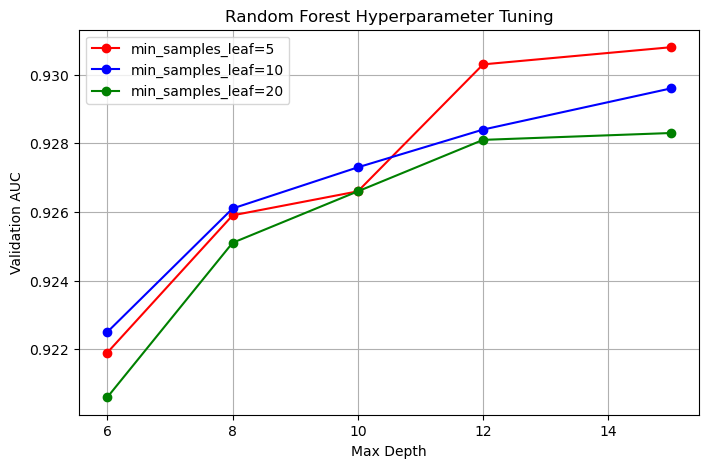

In [49]:
colors = ['red', 'blue', 'green'] 

plt.figure(figsize=(8, 5))

for leaf, color in zip([5, 10, 20], colors):
    subset = results_df[results_df['Leaf'] == leaf]

    plt.plot(
        subset['Depth'],
        subset['Val_AUC'],
        marker='o',
        color=color,
        label=f'min_samples_leaf={leaf}'
    )

plt.title('Random Forest Hyperparameter Tuning')
plt.xlabel('Max Depth')
plt.ylabel('Validation AUC')
plt.legend()
plt.grid()
plt.show()

### Train XGBoost

In [50]:
import xgboost as xgb

feature_names = dv.get_feature_names_out().tolist()

dfulltrain = xgb.DMatrix(
    X_train,
    label=y_train,
    feature_names=feature_names
)

dval = xgb.DMatrix(
    X_val,
    label=y_val,
    feature_names=feature_names
)

In [51]:
xgb_params = {
    'eta': 0.3,
    'max_depth': 6,
    'min_child_weight': 1,
    'objective': 'binary:logistic',
    'eval_metric': 'auc',
    'seed': 1
}

model_xgb = xgb.train(
    xgb_params,
    dfulltrain,
    num_boost_round=100
)

In [52]:
y_train_proba = model_xgb.predict(dfulltrain)
y_val_proba = model_xgb.predict(dval)

In [53]:
y_train_proba = (y_train_proba >= 0.5)
y_val_proba = (y_val_proba >= 0.5)

In [54]:
print('Training Accuracy:', accuracy_score(y_train, y_train_pred))
print('Validation Accuracy:', accuracy_score(y_val, y_val_pred))

print('Training ROC-AUC:', roc_auc_score(y_train, y_train_proba))
print('Validation ROC-AUC:', roc_auc_score(y_val, y_val_proba))

Training Accuracy: 0.9110570424439037
Validation Accuracy: 0.8969991889699919
Training ROC-AUC: 0.978344069585675
Validation ROC-AUC: 0.7735652339942317


In [55]:
xgb_params = {
    'eta': 0.05,
    'max_depth': 3,
    'min_child_weight': 10,
    'objective': 'binary:logistic',
    'eval_metric': 'auc',
    'seed': 1
}

model_xgb = xgb.train(
    xgb_params,
    dfulltrain,
    num_boost_round=300
)

In [56]:
y_train_proba = model_xgb.predict(dfulltrain)
y_val_proba = model_xgb.predict(dval)

y_train_pred = (y_train_proba >= 0.5)
y_val_pred = (y_val_proba >= 0.5)

print('Training Accuracy:', accuracy_score(y_train, y_train_pred))
print('Validation Accuracy:', accuracy_score(y_val, y_val_pred))

print('Training ROC-AUC:', roc_auc_score(y_train, y_train_proba))
print('Validation ROC-AUC:', roc_auc_score(y_val, y_val_proba))

Training Accuracy: 0.9207894025412273
Validation Accuracy: 0.9006488240064883
Training ROC-AUC: 0.9537741998966813
Validation ROC-AUC: 0.9322273417009175


In [57]:
for depth in [2, 3, 4, 5]:

    params = {
        'eta': 0.05,
        'max_depth': depth,
        'min_child_weight': 10,
        'objective': 'binary:logistic',
        'eval_metric': 'auc',
        'seed': 1
    }

    model_xgb = xgb.train(
        params,
        dfulltrain,
        num_boost_round=300
    )

    train_auc = roc_auc_score(
        y_train, model_xgb.predict(dfulltrain)
    )

    val_auc = roc_auc_score(
        y_val, model_xgb.predict(dval)
    )

    print(
        f'depth={depth}, '
        f'train_auc={train_auc:.4f}, '
        f'val_auc={val_auc:.4f}'
    )

depth=2, train_auc=0.9394, val_auc=0.9307
depth=3, train_auc=0.9538, val_auc=0.9322
depth=4, train_auc=0.9640, val_auc=0.9319
depth=5, train_auc=0.9714, val_auc=0.9322


In [58]:
for child_weight in [1, 5, 10, 20, 30]:

    params = {
        'eta': 0.05,
        'max_depth': 2,
        'min_child_weight': child_weight,
        'objective': 'binary:logistic',
        'eval_metric': 'auc',
        'seed': 1
    }

    model_xgb = xgb.train(
        params,
        dfulltrain,
        num_boost_round=300
    )

    train_auc = roc_auc_score(
        y_train, model_xgb.predict(dfulltrain)
    )

    val_auc = roc_auc_score(
        y_val, model_xgb.predict(dval)
    )

    print(
        f'min_child_weight={child_weight}, '
        f'train_auc={train_auc:.4f}, '
        f'val_auc={val_auc:.4f}'
    )

min_child_weight=1, train_auc=0.9419, val_auc=0.9316
min_child_weight=5, train_auc=0.9406, val_auc=0.9313
min_child_weight=10, train_auc=0.9394, val_auc=0.9307
min_child_weight=20, train_auc=0.9392, val_auc=0.9323
min_child_weight=30, train_auc=0.9374, val_auc=0.9318


### Train CatBoost

In [59]:
from catboost import CatBoostClassifier

In [60]:
cat_train = df_train[categorical + numerical].copy()
cat_val = df_val[categorical + numerical].copy()

for col in categorical:
    cat_train[col] = cat_train[col].astype(str)
    cat_val[col] = cat_val[col].astype(str)

y_train = df_train.revenue.astype(int)
y_val = df_val.revenue.astype(int)

In [61]:
cat_model = CatBoostClassifier(
    iterations=500,
    depth=6,
    learning_rate=0.05,
    loss_function='Logloss',
    eval_metric='AUC',
    random_seed=1,
    verbose=100
)

cat_model.fit(
    cat_train,
    y_train,
    cat_features=categorical,
    eval_set=(cat_val, y_val),
    early_stopping_rounds=50
)

0:	test: 0.8797011	best: 0.8797011 (0)	total: 231ms	remaining: 1m 55s
100:	test: 0.9356792	best: 0.9356792 (100)	total: 7.19s	remaining: 28.4s
200:	test: 0.9358161	best: 0.9359757 (164)	total: 13.5s	remaining: 20.2s
Stopped by overfitting detector  (50 iterations wait)

bestTest = 0.935975671
bestIteration = 164

Shrink model to first 165 iterations.


CatBoostClassifier(depth=6, eval_metric='AUC', iterations=500, learning_rate=0.05, loss_function='Logloss', random_seed=1, verbose=100)

In [62]:
y_train_pred = cat_model.predict_proba(cat_train)[:, 1]
y_val_pred = cat_model.predict_proba(cat_val)[:, 1]

print("Train AUC:", roc_auc_score(y_train, y_train_pred))
print("Val AUC:", roc_auc_score(y_val, y_val_pred))

Train AUC: 0.9502522581352131
Val AUC: 0.9359756710313433


In [63]:
depths = [4, 5, 7, 8]

for depth in depths:
    model = CatBoostClassifier(
        iterations=500,
        depth=depth,
        learning_rate=0.05,
        loss_function='Logloss',
        eval_metric='AUC',
        random_seed=1,
        verbose=False
    )

    model.fit(
        cat_train,
        y_train,
        cat_features=categorical,
        eval_set=(cat_val, y_val),
        early_stopping_rounds=50,
        verbose=False
    )

    train_auc = roc_auc_score(
        y_train, model.predict_proba(cat_train)[:, 1]
    )
    val_auc = roc_auc_score(
        y_val, model.predict_proba(cat_val)[:, 1]
    )

    print(
        f"depth={depth}, "
        f"best_iteration={model.best_iteration_}, "
        f"train_auc={train_auc:.4f}, "
        f"val_auc={val_auc:.4f}"
    )

depth=4, best_iteration=276, train_auc=0.9456, val_auc=0.9355
depth=5, best_iteration=249, train_auc=0.9506, val_auc=0.9370
depth=7, best_iteration=127, train_auc=0.9528, val_auc=0.9364
depth=8, best_iteration=108, train_auc=0.9576, val_auc=0.9367


In [64]:
learning_rates = [0.01, 0.03, 0.05, 0.1]

for lr in learning_rates:
    model = CatBoostClassifier(
        iterations=1000,
        depth=5,
        learning_rate=lr,
        loss_function='Logloss',
        eval_metric='AUC',
        random_seed=1,
        verbose=False
    )

    model.fit(
        cat_train,
        y_train,
        cat_features=categorical,
        eval_set=(cat_val, y_val),
        early_stopping_rounds=50,
        verbose=False
    )

    train_auc = roc_auc_score(
        y_train, model.predict_proba(cat_train)[:, 1]
    )
    val_auc = roc_auc_score(
        y_val, model.predict_proba(cat_val)[:, 1]
    )

    print(
        f"lr={lr}, best_iteration={model.best_iteration_}, "
        f"train_auc={train_auc:.4f}, val_auc={val_auc:.4f}"
    )

lr=0.01, best_iteration=999, train_auc=0.9471, val_auc=0.9363
lr=0.03, best_iteration=351, train_auc=0.9487, val_auc=0.9370
lr=0.05, best_iteration=249, train_auc=0.9506, val_auc=0.9370
lr=0.1, best_iteration=75, train_auc=0.9447, val_auc=0.9351


In [65]:
# L2 regularization
l2_values = [1, 3, 5, 7, 9]

for l2 in l2_values:
    model = CatBoostClassifier(
        iterations=1000,
        depth=5,
        learning_rate=0.05,
        l2_leaf_reg=l2,
        loss_function='Logloss',
        eval_metric='AUC',
        random_seed=1,
        verbose=False
    )

    model.fit(
        cat_train,
        y_train,
        cat_features=categorical,
        eval_set=(cat_val, y_val),
        early_stopping_rounds=50,
        verbose=False
    )

    train_auc = roc_auc_score(
        y_train, model.predict_proba(cat_train)[:, 1]
    )
    val_auc = roc_auc_score(
        y_val, model.predict_proba(cat_val)[:, 1]
    )

    print(
        f"l2={l2}, best_iteration={model.best_iteration_}, "
        f"train_auc={train_auc:.4f}, val_auc={val_auc:.4f}"
    )

l2=1, best_iteration=222, train_auc=0.9513, val_auc=0.9365
l2=3, best_iteration=249, train_auc=0.9506, val_auc=0.9370
l2=5, best_iteration=250, train_auc=0.9492, val_auc=0.9369
l2=7, best_iteration=217, train_auc=0.9478, val_auc=0.9373
l2=9, best_iteration=178, train_auc=0.9438, val_auc=0.9358


In [66]:
random_strengths = [0, 0.5, 1, 2, 5]

for rs in random_strengths:
    model = CatBoostClassifier(
        iterations=1000,
        depth=5,
        learning_rate=0.05,
        l2_leaf_reg=7,
        random_strength=rs,
        loss_function='Logloss',
        eval_metric='AUC',
        random_seed=1,
        verbose=False
    )

    model.fit(
        cat_train,
        y_train,
        cat_features=categorical,
        eval_set=(cat_val, y_val),
        early_stopping_rounds=50,
        verbose=False
    )

    train_auc = roc_auc_score(
        y_train, model.predict_proba(cat_train)[:, 1]
    )

    val_auc = roc_auc_score(
        y_val, model.predict_proba(cat_val)[:, 1]
    )

    print(
        f"random_strength={rs}, "
        f"best_iteration={model.best_iteration_}, "
        f"train_auc={train_auc:.4f}, "
        f"val_auc={val_auc:.4f}"
    )

random_strength=0, best_iteration=307, train_auc=0.9543, val_auc=0.9366
random_strength=0.5, best_iteration=279, train_auc=0.9516, val_auc=0.9366
random_strength=1, best_iteration=217, train_auc=0.9478, val_auc=0.9373
random_strength=2, best_iteration=358, train_auc=0.9519, val_auc=0.9359
random_strength=5, best_iteration=382, train_auc=0.9494, val_auc=0.9357


### Train LightGBM

In [67]:
import lightgbm

In [68]:
lgb_train = df_train[categorical + numerical].copy()
lgb_val = df_val[categorical + numerical].copy()

for col in categorical:
    lgb_train[col] = lgb_train[col].astype('category')
    lgb_val[col] = lgb_val[col].astype('category')

y_train = df_train.revenue.astype(int)
y_val = df_val.revenue.astype(int)

In [86]:
from lightgbm import LGBMClassifier, early_stopping
from sklearn.metrics import roc_auc_score

lgb_model = LGBMClassifier(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=-1,
    num_leaves=31,
    n_jobs=-1,
    verbosity=-1
)

lgb_model.fit(
    lgb_train,
    y_train,
    eval_X=lgb_val,
    eval_y=y_val,
    eval_metric='auc',
    callbacks=[
        early_stopping(50)
    ]
)

Training until validation scores don't improve for 50 rounds
Early stopping, best iteration is:
[50]	valid_0's auc: 0.936834	valid_0's binary_logloss: 0.227066


,boosting_type,'gbdt'
,num_leaves,31
,max_depth,-1
,learning_rate,0.05
,n_estimators,500
,subsample_for_bin,200000
,objective,None
,class_weight,None
,min_split_gain,0.0
,min_child_weight,0.001
,min_child_samples,20


In [70]:
from lightgbm import LGBMClassifier, early_stopping, log_evaluation
from sklearn.metrics import roc_auc_score

lgb_model = LGBMClassifier(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=-1,
    num_leaves=31,
    random_state=1,
    n_jobs=-1,
    verbosity=-1
)

lgb_model.fit(
    lgb_train,
    y_train,
    eval_X=lgb_val,
    eval_y=y_val,
    eval_metric='auc',
    callbacks=[
        early_stopping(50),
        log_evaluation(100)
    ]
)

Training until validation scores don't improve for 50 rounds
[100]	valid_0's auc: 0.933993	valid_0's binary_logloss: 0.22601
Early stopping, best iteration is:
[50]	valid_0's auc: 0.936834	valid_0's binary_logloss: 0.227066


,boosting_type,'gbdt'
,num_leaves,31
,max_depth,-1
,learning_rate,0.05
,n_estimators,500
,subsample_for_bin,200000
,objective,None
,class_weight,None
,min_split_gain,0.0
,min_child_weight,0.001
,min_child_samples,20


In [71]:
num_leaves_values = [7, 15, 20, 31, 40, 50]

results = []

for leaves in num_leaves_values:
    model = LGBMClassifier(
        n_estimators=1000,
        learning_rate=0.05,
        max_depth=-1,
        num_leaves=leaves,
        random_state=1,
        n_jobs=-1,
        verbosity=-1
    )

    model.fit(
        lgb_train,
        y_train,
        eval_X=lgb_val,
        eval_y=y_val,
        eval_metric='auc',
        callbacks=[
            early_stopping(50, verbose=False)
        ]
    )

    train_auc = roc_auc_score(
        y_train, model.predict_proba(lgb_train)[:, 1]
    )

    val_auc = roc_auc_score(
        y_val, model.predict_proba(lgb_val)[:, 1]
    )

    results.append({
        'Num_Leaves': leaves,
        'Best_Iteration': model.best_iteration_,
        'Train_AUC': train_auc,
        'Val_AUC': val_auc
    })

results_df = pd.DataFrame(results)

print(results_df.round(4).to_string(index=False))

 Num_Leaves  Best_Iteration  Train_AUC  Val_AUC
          7             113     0.9465   0.9366
         15              51     0.9511   0.9363
         20              42     0.9538   0.9366
         31              50     0.9655   0.9368
         40              37     0.9664   0.9357
         50              53     0.9777   0.9349


In [72]:
depth_values = [3, 4, 5, 6, 8, -1]

results = []

for depth in depth_values:
    model = LGBMClassifier(
        n_estimators=1000,
        learning_rate=0.05,
        max_depth=depth,
        num_leaves=31,
        random_state=1,
        n_jobs=-1,
        verbosity=-1
    )

    model.fit(
        lgb_train,
        y_train,
        eval_X=lgb_val,
        eval_y=y_val,
        eval_metric='auc',
        callbacks=[
            early_stopping(50, verbose=False)
        ]
    )

    train_auc = roc_auc_score(
        y_train, model.predict_proba(lgb_train)[:, 1]
    )

    val_auc = roc_auc_score(
        y_val, model.predict_proba(lgb_val)[:, 1]
    )

    results.append({
        'Max_Depth': depth,
        'Best_Iteration': model.best_iteration_,
        'Train_AUC': train_auc,
        'Val_AUC': val_auc
    })

depth_results = pd.DataFrame(results)

print(depth_results.round(4).to_string(index=False))

 Max_Depth  Best_Iteration  Train_AUC  Val_AUC
         3             113     0.9448   0.9369
         4              68     0.9493   0.9361
         5              44     0.9533   0.9372
         6              45     0.9586   0.9357
         8              53     0.9652   0.9362
        -1              50     0.9655   0.9368


In [73]:
min_child_values = [5, 10, 20, 30, 50, 100]

results = []

for samples in min_child_values:
    model = LGBMClassifier(
        n_estimators=1000,
        learning_rate=0.05,
        max_depth=5,
        num_leaves=31,
        min_child_samples=samples,
        random_state=1,
        n_jobs=-1,
        verbosity=-1
    )

    model.fit(
        lgb_train,
        y_train,
        eval_X=lgb_val,
        eval_y=y_val,
        eval_metric='auc',
        callbacks=[early_stopping(50, verbose=False)]
    )

    train_auc = roc_auc_score(
        y_train, model.predict_proba(lgb_train)[:, 1]
    )

    val_auc = roc_auc_score(
        y_val, model.predict_proba(lgb_val)[:, 1]
    )

    results.append({
        'Min_Child_Samples': samples,
        'Best_Iteration': model.best_iteration_,
        'Train_AUC': train_auc,
        'Val_AUC': val_auc
    })

min_child_results = pd.DataFrame(results)

print(min_child_results.round(4).to_string(index=False))

 Min_Child_Samples  Best_Iteration  Train_AUC  Val_AUC
                 5              33     0.9527   0.9367
                10              50     0.9562   0.9374
                20              44     0.9533   0.9372
                30              55     0.9550   0.9373
                50              35     0.9495   0.9368
               100              48     0.9491   0.9367


In [74]:
learning_rates = [0.01, 0.03, 0.05, 0.1]

results = []

for lr in learning_rates:
    model = LGBMClassifier(
        n_estimators=2000,
        learning_rate=lr,
        max_depth=5,
        num_leaves=31,
        min_child_samples=10,
        random_state=1,
        n_jobs=-1,
        verbosity=-1
    )

    model.fit(
        lgb_train,
        y_train,
        eval_X=lgb_val,
        eval_y=y_val,
        eval_metric='auc',
        callbacks=[early_stopping(50, verbose=False)]
    )

    train_auc = roc_auc_score(
        y_train, model.predict_proba(lgb_train)[:, 1]
    )

    val_auc = roc_auc_score(
        y_val, model.predict_proba(lgb_val)[:, 1]
    )

    results.append({
        'Learning_Rate': lr,
        'Best_Iteration': model.best_iteration_,
        'Train_AUC': train_auc,
        'Val_AUC': val_auc
    })

lr_results = pd.DataFrame(results)

print(lr_results.round(4).to_string(index=False))

 Learning_Rate  Best_Iteration  Train_AUC  Val_AUC
          0.01             169     0.9521   0.9370
          0.03              84     0.9555   0.9368
          0.05              50     0.9562   0.9374
          0.10              23     0.9555   0.9373


### Comparison table

In [75]:
comparison = [
    ('Logistic Regression', 0.9044, 0.8990),
    ('Decision Tree',       0.9345, 0.9213),
    ('Random Forest',       0.9888, 0.9333),
    ('XGBoost',              0.9512, 0.9338),
    ('CatBoost',             0.9478, 0.9373),
    ('LightGBM',             0.9562, 0.9374)
]

results_df = pd.DataFrame(
    comparison,
    columns=['Model', 'Train_AUC', 'Val_AUC']
)

results_df['AUC_Gap'] = (
    results_df['Train_AUC'] - results_df['Val_AUC']
)

results_df = results_df.sort_values(
    by='Val_AUC', ascending=False
)

print(results_df.round(4).to_string(index=False))

              Model  Train_AUC  Val_AUC  AUC_Gap
           LightGBM     0.9562   0.9374   0.0188
           CatBoost     0.9478   0.9373   0.0105
            XGBoost     0.9512   0.9338   0.0174
      Random Forest     0.9888   0.9333   0.0555
      Decision Tree     0.9345   0.9213   0.0132
Logistic Regression     0.9044   0.8990   0.0054


### Final LightGBM training

In [76]:
best_lgb_params = {
    'n_estimators': 50,
    'learning_rate': 0.05,
    'max_depth': 5,
    'num_leaves': 31,
    'min_child_samples': 10,
    'random_state': 1,
    'n_jobs': -1,
    'verbosity': -1
}

In [77]:
lgb_full_train = df_full_train[categorical + numerical].copy()
lgb_test = df_test[categorical + numerical].copy()

for col in categorical:
    lgb_full_train[col] = lgb_full_train[col].astype('category')

    lgb_test[col] = pd.Categorical(
        lgb_test[col],
        categories=lgb_full_train[col].cat.categories
    )

y_full_train = df_full_train.revenue.astype(int)
y_test = df_test.revenue.astype(int)

In [78]:
final_model = LGBMClassifier(**best_lgb_params)

final_model.fit(
    lgb_full_train,
    y_full_train
)

,boosting_type,'gbdt'
,num_leaves,31
,max_depth,5
,learning_rate,0.05
,n_estimators,50
,subsample_for_bin,200000
,objective,None
,class_weight,None
,min_split_gain,0.0
,min_child_weight,0.001
,min_child_samples,10


In [79]:
y_pred = final_model.predict(lgb_test)
y_pred_proba = final_model.predict_proba(lgb_test)[:, 1]

test_auc = roc_auc_score(y_test, y_pred_proba)
test_accuracy = accuracy_score(y_test, y_pred)

print('Test AUC:', round(test_auc, 4))
print('Test Accuracy:', round(test_accuracy, 4))

Test AUC: 0.9398
Test Accuracy: 0.9088


In [80]:
from sklearn.metrics import classification_report 

In [81]:
print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred))

[[2010   74]
 [ 151  231]]
              precision    recall  f1-score   support

           0       0.93      0.96      0.95      2084
           1       0.76      0.60      0.67       382

    accuracy                           0.91      2466
   macro avg       0.84      0.78      0.81      2466
weighted avg       0.90      0.91      0.90      2466



In [82]:
importance = pd.DataFrame({
    'Feature': final_model.booster_.feature_name(),
    'Importance': final_model.booster_.feature_importance(
        importance_type='gain'
    )
})

importance = importance.sort_values(
    by='Importance', ascending=False
)

importance['Importance_%'] = (
    importance['Importance'] / importance['Importance'].sum() * 100
)

print(importance.head(15).round(2).to_string(index=False))

                Feature  Importance  Importance_%
             pagevalues    32538.95         72.10
                  month     3800.69          8.42
         productrelated     1609.22          3.57
            bouncerates     1417.82          3.14
              exitrates     1404.18          3.11
productrelated_duration     1193.80          2.65
         administrative      932.70          2.07
administrative_duration      607.69          1.35
            traffictype      525.95          1.17
            visitortype      457.48          1.01
 informational_duration      208.99          0.46
          informational      183.23          0.41
                weekend      103.05          0.23
             specialday       77.54          0.17
                 region       46.34          0.10


### Prepare data without PageValues

In [83]:
numerical_no_pagevalues = [
    col for col in numerical if col != 'pagevalues'
]

features_no_pagevalues = categorical + numerical_no_pagevalues

lgb_train_no_pv = df_train[features_no_pagevalues].copy()
lgb_val_no_pv = df_val[features_no_pagevalues].copy()

for col in categorical:
    lgb_train_no_pv[col] = lgb_train_no_pv[col].astype('category')
    lgb_val_no_pv[col] = pd.Categorical(
        lgb_val_no_pv[col],
        categories=lgb_train_no_pv[col].cat.categories
    )

### LightGBM without PageValues

In [84]:
model_no_pv = LGBMClassifier(
    **best_lgb_params
)

model_no_pv.fit(
    lgb_train_no_pv,
    y_train,
    eval_X=lgb_val_no_pv,
    eval_y=y_val,
    eval_metric='auc',
    callbacks=[
        early_stopping(50),
        log_evaluation(100)
    ]
)

Training until validation scores don't improve for 50 rounds
Did not meet early stopping. Best iteration is:
[46]	valid_0's auc: 0.783865	valid_0's binary_logloss: 0.361078


,boosting_type,'gbdt'
,num_leaves,31
,max_depth,5
,learning_rate,0.05
,n_estimators,50
,subsample_for_bin,200000
,objective,None
,class_weight,None
,min_split_gain,0.0
,min_child_weight,0.001
,min_child_samples,10


In [85]:
y_pred_no_pv = model_no_pv.predict_proba(
    lgb_val_no_pv
)[:, 1]

auc_no_pv = roc_auc_score(y_val, y_pred_no_pv)

print('Validation AUC without PageValues:', round(auc_no_pv, 4))
print('Validation AUC with PageValues:   ', 0.9374)

Validation AUC without PageValues: 0.7839
Validation AUC with PageValues:    0.9374
